# 04 – Tiền xử lý & đặc trưng văn bản; tinh chỉnh Naive Bayes, Logistic Regression

**Người thực hiện:** loc (Huỳnh Tấn Lộc)  
**Mục tiêu:** Trả lời: tiền xử lý / n-gram / min_df ảnh hưởng thế nào? Chọn cấu hình NB, LR tốt nhất.

**Quy tắc:** chạy TỪNG ô một, đổi tham số rồi chạy lại; mỗi ngày làm xong thì `git add` + `git commit -m "<mô tả đúng việc đã làm>"` + `git push`. Cuối buổi xuất HTML: `python ../scripts/export_notebook_html.py <notebook> loc`.

**Các bước:**
1. Kiểm chứng lại các con số dữ liệu dùng trong báo cáo (tự giải thích ý nghĩa).
2. Thử word_ngram (1,1), (1,2), (1,3) với NB.
3. Thử min_df 1, 2, 5.
4. Quét alpha của NB (ít nhất 5 giá trị).
5. Quét C của Logistic Regression (ít nhất 5 giá trị), có/không class_weight='balanced'.
6. Vẽ đường F1 theo tham số (lưu bằng save_fig) và chọn cấu hình tốt nhất.

In [11]:
import sys, json, pandas as pd, numpy as np, matplotlib.pyplot as plt
sys.path.append('../src')
from run_experiment import run
from figlog import save_fig
from exp_logger import log_generic
from common import load_data, clean_title


## 1. Kiểm chứng số liệu dữ liệu
Mỗi con số trong báo cáo phải chỉ được ra ô code sinh ra nó. Chạy ô dưới, rồi **tự viết** 1–2 câu giải thích ý nghĩa từng số.

In [12]:
df = load_data()
print('Số mẫu:', len(df))
print('Số merchant:', df.merchant_id.nunique())
print('Số cụm thực thể:', df.cluster_id.nunique())
print('Giá trị khuyết:', df.isna().sum().sum())
df.category_label.value_counts()

Số mẫu: 35311
Số merchant: 306
Số cụm thực thể: 13233
Giá trị khuyết: 0


category_label
Fridge Freezers     5501
Mobile Phones       4081
Washing Machines    4044
CPUs                3862
Fridges             3584
TVs                 3564
Dishwashers         3424
Digital Cameras     2697
Microwaves          2342
Freezers            2212
Name: count, dtype: int64

**Giải thích (tự viết):**

- **35.311 mẫu**: mỗi dòng là một tin rao bán sản phẩm trên trang so sánh giá PriceRunner, gồm tên sản phẩm (title), cửa hàng đăng bán và danh mục. Mô hình chỉ dùng title để đoán danh mục.
- **306 merchant**: dữ liệu được gom từ 306 cửa hàng khác nhau. Mỗi cửa hàng đặt tên sản phẩm theo cách riêng (thứ tự từ, viết tắt, mã model), nên cùng một loại sản phẩm có nhiều cách viết khác nhau, khiến bài toán khó hơn.
- **13.233 cụm thực thể**: số sản phẩm thật sự khác nhau. Trung bình mỗi sản phẩm xuất hiện khoảng 2,7 lần, do nhiều cửa hàng cùng bán một sản phẩm. Đây là nhãn thật (ground truth) dùng để đánh giá phần phân cụm.
- **0 giá trị khuyết**: dữ liệu đầy đủ, không cần xử lý thiếu.
- **Phân bố lớp**: lớp nhiều nhất là **Fridge Freezers (5.501 mẫu, khoảng 15,6%)**, lớp ít nhất là **Freezers (2.212 mẫu, khoảng 6,3%)**, chênh nhau khoảng 2,5 lần. Dữ liệu lệch lớp ở mức vừa phải, vì vậy nhóm dùng **Macro-F1** (mỗi lớp có trọng số như nhau) thay vì chỉ dùng Accuracy. Ba lớp tủ lạnh (Fridges, Freezers, Fridge Freezers) có tên sản phẩm gần giống nhau, nên đây là chỗ mô hình dễ nhầm nhất, khớp với kết quả thí nghiệm NB của mình.

In [13]:
# Ví dụ làm sạch tiêu đề: so sánh trước / sau
for t in df.title.sample(8, random_state=0):
    print(f'{t!r:70s} -> {clean_title(t)!r}')

'kodak az651 65 multiplier x'                                          -> 'kodak az651 65 multiplier x'
'beko csg1675w 175x60cm 273l freestanding fridge freezer white'        -> 'beko csg1675w 175x60cm 273l freestanding fridge freezer white'
'datalogic powerscan pbt9500 handheld 1d/2d photo diode black yellow'  -> 'datalogic powerscan pbt9500 handheld 1d 2d photo diode black yellow'
'amd 7th gen amd athlon x4 950 processor'                              -> 'amd 7th gen amd athlon x4 950 processor'
'siemens geschirrsp ler 45 cm speedmatic45 umbra unterbau sr36t498eu'  -> 'siemens geschirrsp ler 45cm speedmatic45 umbra unterbau sr36t498eu'
'whirlpool arg18083a 178cm integrated in column larder fridge'         -> 'whirlpool arg18083a 178cm integrated in column larder fridge'
'hoover hvbfp6182w/hvbfp6182w'                                         -> 'hoover hvbfp6182w hvbfp6182w'
'samsung wf80f5e0w2w washing machine'                                  -> 'samsung wf80f5e0w2w washing machine'


**Nhận xét: hàm clean_title giữ lại gì, bỏ đi gì, tại sao? (tự viết)** 

- **Giữ lại**: tên hãng (beko, whirlpool, samsung...), mã model (csg1675w, wf80f5e0w2w...), con số và đơn vị (273l, 175x60cm, 178cm), kể cả từ không phải tiếng Anh (geschirrsp ler, unterbau). Đây là những thông tin phân biệt danh mục rất mạnh: dung tích "273l" gợi ý tủ lạnh, "45cm" là kích thước điển hình của máy rửa bát, mã model thường có tiền tố riêng theo từng loại sản phẩm.
- **Thay đổi / bỏ đi**:
  - Dấu "/" được thay bằng dấu cách: "1d/2d" thành "1d 2d", "hvbfp6182w/hvbfp6182w" thành 2 từ riêng. Nhờ vậy TF-IDF nhận ra từng mã như một từ bình thường, không bị dính thành một từ lạ chỉ xuất hiện một lần.
  - Số và đơn vị bị tách được ghép lại: "45 cm" thành "45cm". Mỗi cửa hàng viết một kiểu (có hoặc không có dấu cách), ghép lại giúp cùng một thông tin luôn thành cùng một từ.
- **Tại sao làm nhẹ tay như vậy**: dữ liệu đã viết thường sẵn, và tên sản phẩm rất ngắn nên mỗi từ đều có giá trị. Hàm chỉ chuẩn hóa cách viết, không xóa số hay mã model như cách làm sạch văn bản thông thường. Nếu bỏ số và mã model thì mô hình mất đi đặc trưng quan trọng nhất.

## 2. Thí nghiệm n-gram (Naive Bayes)
Đổi `word_ngram` rồi chạy lại ô. Mỗi lần chạy = 1 dòng nhật ký.

In [14]:
for ng, name in [((1, 1), 'ngram_11'), ((1, 2), 'ngram_12'), ((1, 3), 'ngram_13')]:
    res, _ = run(member='loc', model='nb', features='word', params={'alpha': 0.1},
                 word_ngram=ng, exp_name=name, show_report=False)

log = pd.read_csv('../experiments/loc/experiment_log.csv')
log.tail(3)

[loc_20261112_215511] nb/word {'alpha': 0.1} split=strat
   train_time_s                 0.1481
   test_accuracy                0.9561
   test_precision_macro         0.9623
   test_recall_macro            0.9511
   test_f1_macro                0.9555
   test_f1_weighted             0.9559
   f1_Fridges                   0.8890
   f1_Freezers                  0.8783
   f1_Fridge_Freezers           0.9206
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_215511] nb/word {'alpha': 0.1} split=strat
   train_time_s                 0.2262
   test_accuracy                0.9650
   test_precision_macro         0.9696
   test_recall_macro            0.9636
   test_f1_macro                0.9663
   test_f1_weighted             0.9651
   f1_Fridges                   0.9041
   f1_Freezers                  0.9368
   f1_Fridge_Freezers           0.9318
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_2155

,run_id,thoi_diem_chay,may_chay,git_commit,ten_thi_nghiem,model,features,params,split,word_ngram,...,cv_f1_macro_std,test_accuracy,test_f1_macro,test_f1_weighted,f1_Fridges,f1_Freezers,f1_Fridge_Freezers,train_time_s,nhan_xet,rut_ra
3,loc_20261112_215511,2026-11-12 21:55:11,MacBook-Air-cua-Peng.local,e52cbbb,ngram_11,nb,word,"{""alpha"": 0.1}",strat,"[1, 1]",...,NaN,0.956109,0.955485,0.955887,0.889043,0.878294,0.920621,0.148092,NaN,NaN
4,loc_20261112_215511,2026-11-12 21:55:11,MacBook-Air-cua-Peng.local,e52cbbb,ngram_12,nb,word,"{""alpha"": 0.1}",strat,"[1, 2]",...,NaN,0.965029,0.966283,0.965086,0.904072,0.936830,0.931777,0.226247,NaN,NaN
5,loc_20261112_215512,2026-11-12 21:55:12,MacBook-Air-cua-Peng.local,e52cbbb,ngram_13,nb,word,"{""alpha"": 0.1}",strat,"[1, 3]",...,NaN,0.964746,0.965789,0.964808,0.902338,0.931900,0.933094,0.330457,NaN,NaN


> **Nhật ký lần chạy** – ngày giờ đã tự ghi trong `experiments/loc/`.
>
> - **Kết quả chính:** ngram (1,1): F1 = 0.9555 · (1,2): F1 = **0.9663** · (1,3): F1 = 0.9658 (NB, alpha = 0.1).
> - **Nhận xét:** Thêm bigram (1,2) tăng F1 thêm khoảng 0.011 so với chỉ dùng từ đơn. Phần tăng chủ yếu nằm ở nhóm tủ lạnh: Freezers tăng từ 0.878 lên 0.937, Fridges từ 0.889 lên 0.904, vì các cụm như "fridge freezer", "chest freezer", "built in" giúp phân biệt 3 lớp này. Thêm trigram (1,3) không giúp gì (F1 giảm nhẹ 0.0005), trong khi thời gian train tăng gần gấp 1,5 lần: tên sản phẩm rất ngắn nên cụm 3 từ hiếm khi lặp lại, chủ yếu tạo thêm đặc trưng thưa.
> - **Lần sau thử:** giữ ngram (1,2) làm cấu hình chuẩn và chuyển sang thử min_df.

## 3. Thí nghiệm min_df

In [15]:
import time
for m in [1, 2, 5]:
    res, _ = run(member='loc', model='nb', features='word', params={'alpha': 0.1},
                 min_df=m, exp_name=f'mindf_{m}', show_report=False)
    time.sleep(1)

log = pd.read_csv('../experiments/loc/experiment_log.csv')
log[['run_id', 'ten_thi_nghiem', 'test_f1_macro']].tail(3)

[loc_20261112_220159] nb/word {'alpha': 0.1} split=strat
   train_time_s                 0.2650
   test_accuracy                0.9771
   test_precision_macro         0.9805
   test_recall_macro            0.9747
   test_f1_macro                0.9773
   test_f1_weighted             0.9770
   f1_Fridges                   0.9387
   f1_Freezers                  0.9479
   f1_Fridge_Freezers           0.9607
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_220201] nb/word {'alpha': 0.1} split=strat
   train_time_s                 0.2335
   test_accuracy                0.9650
   test_precision_macro         0.9696
   test_recall_macro            0.9636
   test_f1_macro                0.9663
   test_f1_weighted             0.9651
   f1_Fridges                   0.9041
   f1_Freezers                  0.9368
   f1_Fridge_Freezers           0.9318
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_2202

,run_id,ten_thi_nghiem,test_f1_macro
6,loc_20261112_220159,mindf_1,0.977337
7,loc_20261112_220201,mindf_2,0.966283
8,loc_20261112_220203,mindf_5,0.949892


> **Nhật ký lần chạy** – ngày giờ đã tự ghi trong `experiments/loc/`.
>
> - **Kết quả chính:** min_df = 1: F1 = **0.9773** · min_df = 2: F1 = 0.9663 (trùng E01, nghĩa là mặc định của nhóm là min_df = 2) · min_df = 5: F1 = 0.9499 (NB, alpha = 0.1, ngram (1,2)).
> - **Nhận xét:** min_df càng nhỏ thì F1 càng cao. Giữ lại từ chỉ xuất hiện 1 lần giúp F1 tăng thêm khoảng 0.011, vì phần lớn các từ hiếm này là mã model và mã sản phẩm, loại đặc trưng phân biệt danh mục rất mạnh. Ngược lại, min_df = 5 bỏ mất nhiều mã model nên F1 giảm còn 0.950, nhóm tủ lạnh tụt mạnh nhất (Fridges 0.904 xuống 0.869). Lưu ý: dữ liệu có nhiều cửa hàng cùng bán một sản phẩm (35.311 dòng nhưng chỉ 13.233 sản phẩm), nên khi chia ngẫu nhiên, cùng một mã model có thể nằm ở cả train và test, khiến kết quả min_df = 1 có thể hơi lạc quan.
> - **Lần sau thử:** dùng min_df = 1 cho các thí nghiệm tiếp theo; kiểm tra lại bằng cách chia train/test theo cluster_id (sản phẩm) để xem mức tăng có còn giữ được không.

## 4. Quét alpha (Naive Bayes)
Chạy từng giá trị (hoặc vòng lặp nhỏ) – ghi lại nhận xét sau mỗi đợt.

In [16]:
for a in [0.01, 0.03, 0.1, 0.3, 1.0]:
    res, _ = run(member='loc', model='nb', features='word', params={'alpha': a},
                 min_df=1, exp_name=f'alpha_{a}', show_report=False)
    time.sleep(1)

log = pd.read_csv('../experiments/loc/experiment_log.csv')
log[['run_id', 'ten_thi_nghiem', 'test_f1_macro']].tail(5)

[loc_20261112_220341] nb/word {'alpha': 0.01} split=strat
   train_time_s                 0.3611
   test_accuracy                0.9798
   test_precision_macro         0.9804
   test_recall_macro            0.9796
   test_f1_macro                0.9800
   test_f1_weighted             0.9798
   f1_Fridges                   0.9517
   f1_Freezers                  0.9622
   f1_Fridge_Freezers           0.9691
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_220342] nb/word {'alpha': 0.03} split=strat
   train_time_s                 0.2802
   test_accuracy                0.9785
   test_precision_macro         0.9798
   test_recall_macro            0.9780
   test_f1_macro                0.9789
   test_f1_weighted             0.9785
   f1_Fridges                   0.9456
   f1_Freezers                  0.9584
   f1_Fridge_Freezers           0.9651
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_22

,run_id,ten_thi_nghiem,test_f1_macro
9,loc_20261112_220341,alpha_0.01,0.979964
10,loc_20261112_220342,alpha_0.03,0.978862
11,loc_20261112_220344,alpha_0.1,0.977337
12,loc_20261112_220346,alpha_0.3,0.970196
13,loc_20261112_220347,alpha_1.0,0.950069


> **Nhật ký lần chạy** – ngày giờ đã tự ghi trong `experiments/loc/`.
>
> - **Kết quả chính:** (NB, ngram (1,2), min_df = 1) alpha 0.01: F1 = **0.9800** · 0.03: 0.9789 · 0.1: 0.9773 · 0.3: 0.9702 · 1.0: 0.9501.
> - **Nhận xét:** F1 giảm đều khi alpha tăng. alpha nhỏ nghĩa là làm trơn ít, giữ được trọng số cao cho các từ hiếm nhưng phân biệt tốt (mã model, từ riêng của từng loại). alpha = 1.0 làm trơn quá mạnh, mô hình nghiêng về lớp đông nhất (Fridge Freezers), làm F1 của Freezers tụt còn 0.805. Mức chênh giữa 0.01 và 0.1 nhỏ (khoảng 0.003), còn từ 0.1 lên 1.0 thì giảm tới 0.027.
> - **Lần sau thử:** giá trị tốt nhất đang nằm ở biên dưới của khoảng quét (0.01), nên cần thử thêm 0.001 và 0.003 để xem F1 đã đạt đỉnh chưa. Tạm chọn alpha = 0.01.

## 5. Quét C (Logistic Regression)

In [17]:
for cw in [None, 'balanced']:
    for c in [0.3, 1.0, 3.0, 10.0, 30.0]:
        p = {'C': c} if cw is None else {'C': c, 'class_weight': cw}
        name = f'lr_C{c}' + ('' if cw is None else '_bal')
        res, _ = run(member='loc', model='lr', features='word', params=p,
                     min_df=1, exp_name=name, show_report=False)
        time.sleep(1)

log = pd.read_csv('../experiments/loc/experiment_log.csv')
log[['run_id', 'ten_thi_nghiem', 'test_f1_macro', 'train_time_s']].tail(10)

[loc_20261112_220452] lr/word {'C': 0.3} split=strat
   train_time_s                 2.9386
   test_accuracy                0.9439
   test_precision_macro         0.9507
   test_recall_macro            0.9438
   test_f1_macro                0.9460
   test_f1_weighted             0.9444
   f1_Fridges                   0.8639
   f1_Freezers                  0.9255
   f1_Fridge_Freezers           0.9255
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_220457] lr/word {'C': 1.0} split=strat
   train_time_s                 4.0840
   test_accuracy                0.9594
   test_precision_macro         0.9625
   test_recall_macro            0.9596
   test_f1_macro                0.9606
   test_f1_weighted             0.9594
   f1_Fridges                   0.9020
   f1_Freezers                  0.9409
   f1_Fridge_Freezers           0.9411
→ Đã ghi vào experiments/loc/experiment_log.csv. Hãy mở file và điền cột nhan_xet.
[loc_20261112_220503] lr/w

,run_id,ten_thi_nghiem,test_f1_macro,train_time_s
14,loc_20261112_220452,lr_C0.3,0.945964,2.938648
15,loc_20261112_220457,lr_C1.0,0.960644,4.083951
16,loc_20261112_220503,lr_C3.0,0.965059,4.782299
17,loc_20261112_220510,lr_C10.0,0.967274,4.772182
18,loc_20261112_220516,lr_C30.0,0.967577,4.986112
19,loc_20261112_220520,lr_C0.3_bal,0.947106,2.436004
20,loc_20261112_220526,lr_C1.0_bal,0.954848,4.697291
21,loc_20261112_220532,lr_C3.0_bal,0.962806,4.009209
22,loc_20261112_220538,lr_C10.0_bal,0.964876,4.936622
23,loc_20261112_220545,lr_C30.0_bal,0.967126,5.731189


> **Nhật ký lần chạy** – ngày giờ đã tự ghi trong `experiments/loc/`.
>
> - **Kết quả chính:** (LR, ngram (1,2), min_df = 1) C = 0.3 / 1 / 3 / 10 / 30: F1 = 0.9460 / 0.9606 / 0.9651 / 0.9673 / **0.9676**. Có class_weight='balanced': 0.9471 / 0.9548 / 0.9628 / 0.9649 / 0.9671.
> - **Nhận xét:** C càng lớn (regularization càng yếu) thì F1 càng cao, nhưng tăng chậm dần và gần như bão hòa từ C = 10 (C = 10 lên 30 chỉ tăng thêm 0.0003). Với dữ liệu văn bản nhiều đặc trưng thưa như mã model, mô hình cần ít regularization để tận dụng các từ hiếm. class_weight='balanced' không giúp ích (thấp hơn hoặc bằng ở hầu hết các C), vì dữ liệu chỉ lệch lớp vừa phải (khoảng 2,5 lần). LR tốt nhất (0.9676) vẫn thấp hơn NB tốt nhất (0.9800), trong khi train lâu hơn khoảng 15–20 lần (khoảng 5 giây so với khoảng 0.3 giây).
> - **Lần sau thử:** chọn C = 10 (gần bằng C = 30 nhưng ổn định hơn), không dùng balanced; có thể thử C = 100 để chắc chắn đã bão hòa.

## 6. Tổng hợp & vẽ
Đọc lại nhật ký của mình, vẽ F1 theo tham số.

In [21]:
log = pd.read_csv('../experiments/loc/experiment_log.csv')

nb = log[log.ten_thi_nghiem.str.match(r'alpha_\d+\.\d+')].copy()
nb['alpha'] = nb.params.map(lambda s: json.loads(s).get('alpha'))

lr = log[log.ten_thi_nghiem.str.startswith('lr_C')].copy()
lr['C'] = lr.params.map(lambda s: json.loads(s).get('C'))
lr['bal'] = lr.ten_thi_nghiem.str.endswith('_bal')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(nb.alpha, nb.test_f1_macro, 'o-')
axes[0].set(xscale='log', xlabel='alpha', ylabel='Macro-F1 (Test)', title='NB: Macro-F1 theo alpha')
for b, lab in [(False, 'không balanced'), (True, 'balanced')]:
    d = lr[lr.bal == b]
    axes[1].plot(d.C, d.test_f1_macro, 'o-', label=lab)
axes[1].set(xscale='log', xlabel='C', ylabel='Macro-F1 (Test)', title='LR: Macro-F1 theo C')
axes[1].legend()
plt.tight_layout()

save_fig(fig, 'loc_nb_alpha_lr_C', notebook='04_Loc_TienXuLy_NB_LR.ipynb', member='loc', cell='Mục 6',
         y_nghia='NB tốt nhất ở alpha nhỏ (0.01, F1=0.980); LR tăng theo C và bão hòa từ C=10 (F1≈0.967); balanced không giúp ích.')

Đã lưu loc_nb_alpha_lr_C.png (ghi nguồn vào figures/FIGURE_INDEX.csv)


PosixPath('/Users/peng/Desktop/mayhoc/DoAnCuoiKy/figures/loc_nb_alpha_lr_C.png')

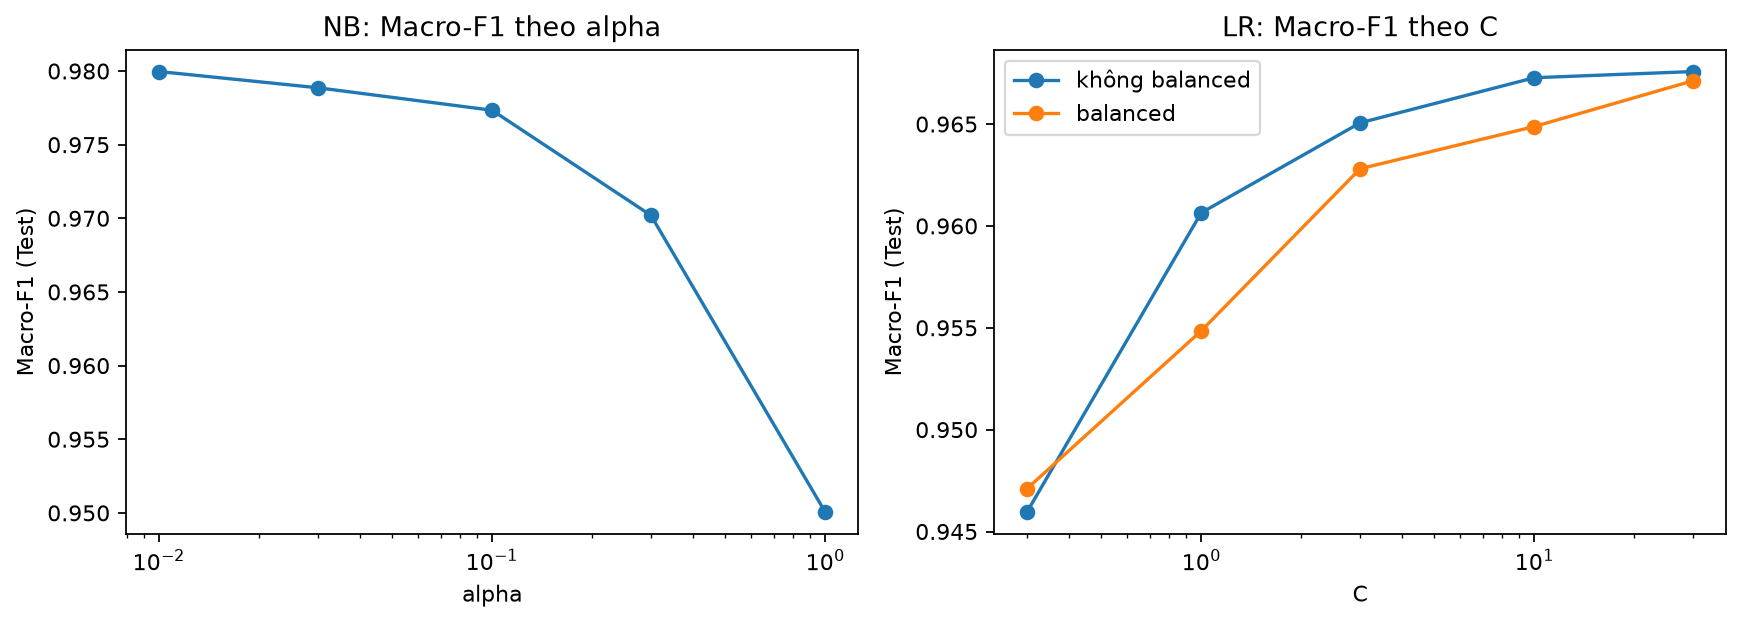

In [22]:
from IPython.display import Image
Image('../figures/loc_nb_alpha_lr_C.png')

## 7. Kết luận của Lộc 

- **Cấu hình chọn:** Naive Bayes, TF-IDF từ với ngram (1,2), **min_df = 1**, **alpha = 0.01**, đạt Macro-F1 = **0.9800** (tăng khoảng 0.014 so với E01 giữa kỳ là 0.9663). Logistic Regression tốt nhất (C = 10–30, không balanced) chỉ đạt khoảng 0.967.
- **Vì sao:**
  - NB cao hơn LR khoảng 0.012 và train nhanh hơn khoảng 15 lần (0.3 giây so với 5 giây).
  - Tên sản phẩm ngắn, đặc trưng chủ yếu là các từ rời rạc (hãng, mã model, đơn vị như "273l", "45cm"), rất hợp với NB.
  - min_df = 1 và alpha nhỏ giữ lại và tin tưởng các từ hiếm, chủ yếu là mã model, vốn phân biệt danh mục tốt nhất.
  - Bigram (1,2) giúp tách nhóm tủ lạnh nhờ các cụm như "fridge freezer", "chest freezer"; trigram không giúp thêm.
- **Hạn chế:**
  - Train/test chia ngẫu nhiên theo dòng, nhưng cùng một sản phẩm được nhiều cửa hàng đăng (35.311 dòng, chỉ 13.233 sản phẩm), nên mã model có thể có ở cả hai tập. Vì vậy kết quả min_df = 1 và alpha nhỏ có thể hơi lạc quan, cần kiểm tra lại bằng cách chia theo cluster_id.
  - Mới chia 1 lần, chưa chạy cross-validation, nên các chênh lệch rất nhỏ (dưới 0.002, ví dụ alpha 0.01 so với 0.03) chưa chắc có ý nghĩa.
  - alpha tốt nhất nằm ở biên khoảng quét (0.01), cần thử thêm 0.001 và 0.003.
  - Nhóm tủ lạnh (Fridges, Freezers, Fridge Freezers) vẫn là điểm yếu chung của mọi cấu hình.
  